# End-to-end optimization of TX and RX DSP through a digital surrogate

Fig. 2 of the OFC 2027 paper *End-to-End Optimization of Direct-Detection Optical Systems*: IM/DD link at
20 GBd, 40 Gbps, over 10 km of standard single-mode fiber (chromatic dispersion index γ = 0.69). For every
configuration selected in the knobs (noise regime, format, TX filter bandwidth, filters, converters, fiber),
these methods are compared on the same held-out data:

* **Linear FFE**: least-squares linear feed-forward equalizer (two FIR filters for BPAM-4, one for PAM-4), conventional TX;
* **RX-only NN**: conventional TX, NN receiver;
* **E2E-NN**: TX NN and RX NN trained jointly through a digital surrogate of the analog link;
* **E2E-LUT-DT**: the E2E system simplified, the TX NN as its lookup table and decision trees in place
  of the RX NNs, without multiplications.

The DSPs are trained through the digital surrogate and evaluated on the reference simulator.
Every transmitter is normalized to unit mean optical power, in both noise regimes (Secondini's
convention), and all bandwidths scale with the symbol rate.
Results are cached in `results/ofc_e2e/` per configuration: a configuration already computed
is loaded, a new one is trained. `FORCE_RETRAIN` recomputes the selected configurations.
`INITIALIZATION` sets how the E2E-NN starts: `"warmstart"` (the paper's figures) or `"zero-mean"`
(TX NN and RX NN from random weights, section 3).
The required SNR versus chromatic dispersion (Fig. 3) is in `ofc_dispersion.ipynb`, with the same
knobs; its 10-km configurations are the ones of this notebook.

## 1. Setup and knobs

In [1]:
# Resolve paths independently of the notebook's working directory.
from dataclasses import replace
from pathlib import Path
import os
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "functions" / "link.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

%load_ext autoreload
%autoreload 2

import shutil
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

from functions.dsp import ConventionalTransmitter, ReceiverNN, TransmitterNN, precode
from functions.link import Link
from functions.parameters import Budget, Case, LinkParameters, EVALUATION_LEVEL_DB
from functions.pipeline import case_folder, extra_points, run_case, training_folder

%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ---------------- knobs ----------------
INITIALIZATION   = "zero-mean"                 # E2E start: "warmstart", the paper's (RX NN trained with the
                                               # conventional TX, TX NN fitted to the conventional voltages, then
                                               # joint training), or "zero-mean" (TX NN and RX NN from random
                                               # weights; TX NN output with zero mean, functions.dsp.ZeroMeanTransmitter)
REGIMES          = ["electrical", "optical"]   # noise: "electrical" (thermal) and/or "optical" (ASE)
FORMAT           = {"electrical": "pam4", "optical": "bpam"}
TX_BANDWIDTH_GHZ = [10, 5]                     # TX filter 3-dB bandwidth: 0.5 and 0.25 Rs at 20 GBd
TX_PULSE         = "nrz"                       # "nrz" or "rrc"
TX_FILTER        = "gaussian"                  # H_TX, analog after the DAC: "gaussian", "rectangular" or "none"
OPTICAL_FILTER   = {"electrical": "none", "optical": "supergaussian"}   # H_opt per noise regime: none without
                                               # ASE, the super-Gaussian for ASE ("waveshaper", "gaussian" too)
OPTICAL_FILTER_GHZ = 30                        # full 3-dB width of the super-Gaussian H_opt: 1.5 Rs at 20 GBd
SUPERGAUSSIAN_ORDER = 4
RX_FILTER        = "gaussian"                  # H_RX: "gaussian" or "none"
RX_FILTER_GHZ    = 10
RX_FILTER_BEFORE_ADC = True                   # True: analog H_RX before the ADC (photodiode and ADC electronics),
                                              # refitted by the digital surrogate; False: digital H_RX after the ADC
DAC_BITS         = 6                           # None: ideal converter
ADC_BITS         = 6
FIBER_KM         = 10.                         # settings enter the cache keys as written: 10. and 10 give different keys
BETA2_PS2_PER_KM = -21.7                       # C-band standard single-mode fiber
MZM_BIAS         = "null"                      # "null"; "quadrature" for PAM-4 only (full intensity range within
                                               # the same peak-to-peak drive swing, relevant with "laser")
ANALOG_SPS       = 2                           # samples per symbol of the analog simulation
RX_SPS           = {"electrical": 1, "optical": 2}   # ADC and RX DSP samples per symbol: one for PAM-4 with
                                               # thermal noise (pulse centres), two for BPAM (sign change between pulses)
POWER_REFERENCE  = "mean"                      # Secondini's: every TX at unit mean optical power, SNR and OSNR
                                               # referred to it; "laser": fixed laser power and driver gain;
                                               # None: "laser" for thermal noise, "mean" for ASE
PRECODE          = True                        # differential precoding of the BPAM sign bit
TRAINING_LEVEL_DB = {"electrical": 18.92, "optical": 16.05}   # SNR or OSNR during training
METHODS          = ["linear", "rx_only", "e2e"]
SURROGATE_STEPS  = 40_000                      # digital-surrogate fit
RX_STEPS         = 100_000                     # RX initialization with the conventional TX
TX_STEPS         = 8_000                       # TX NN fitted to the conventional voltages
E2E_STEPS        = 300_000                     # TX NN and RX NN trained jointly (100_000 for exploratory studies)
RX_ONLY_STEPS    = 300_000                     # RX-only reference, continued from the RX initialization
EVAL_BLOCKS      = 128                         # held-out blocks of 32768 symbols per level, at least (more until 200 errors)
SEED             = {"warmstart": 0, "zero-mean": 3}   # seed of each E2E start
LABEL            = {"electrical": "htx_surrogate_mean_rx1sps_300k", "optical": "htx_surrogate_300k"}   # suffix of
                                               # the configuration names, part of the cache key: the labels of the
                                               # cached cases
FORCE_RETRAIN    = False                       # True: delete and recompute the selected configurations
TREE_LEAVES      = 1024                        # RX decision trees of the E2E system: leaves per tree (2047 nodes);
                                               # None: no trees
TREE_STRUCTURE   = None                        # "symbol", "bit" or None, as the RX NNs (PAM-4: one tree per symbol;
                                               # BPAM: one per bit, amplitude and sign)
TREE_SOURCE      = "surrogate"                 # training windows of the trees: "surrogate" (generated through the
                                               # digital surrogate, as the training data of the NNs) or "simulator"
SNR_RANGE_DB     = (13, 22)                    # common SNR axis (Es/N0) of the BER figure; test levels of the trees

# Additional configurations (empty list: none). Each entry changes one setting of a base configuration.
VARIANTS = [
    # dict(regime="optical", tx_bandwidth_ghz=10, training_level_db=14.05, label="gaussian_tx_trained-2dB"),
    # dict(regime="electrical", tx_bandwidth_ghz=10, training_level_db=16.92, label="gaussian_tx_mean_trained-2dB"),
]

WORK = PROJECT_ROOT / "results" / "ofc_e2e"
BUDGET = Budget(surrogate_steps=SURROGATE_STEPS, rx_steps=RX_STEPS, tx_steps=TX_STEPS, joint_steps=E2E_STEPS,
                rx_only_steps=RX_ONLY_STEPS, eval_blocks=EVAL_BLOCKS)
LINKS = {regime: LinkParameters(tx_pulse=TX_PULSE, tx_filter=TX_FILTER, optical_filter=OPTICAL_FILTER[regime],
                                optical_gaussian_bandwidth=OPTICAL_FILTER_GHZ * 1e9,
                                optical_supergaussian_order=SUPERGAUSSIAN_ORDER, rx_filter=RX_FILTER,
                                rx_filter_bandwidth=RX_FILTER_GHZ * 1e9, rx_filter_before_adc=RX_FILTER_BEFORE_ADC,
                                dac_bits=DAC_BITS, adc_bits=ADC_BITS, fiber_length_km=FIBER_KM,
                                beta2_ps2_per_km=BETA2_PS2_PER_KM, analog_sps=ANALOG_SPS,
                                power_reference=POWER_REFERENCE, mzm_bias=MZM_BIAS,
                                rx_sps=None if RX_SPS[regime] == 2 else RX_SPS[regime])   # None: as the DSP
         for regime in ("electrical", "optical")}
RS_GHZ = LINKS["optical"].symbol_rate / 1e9    # symbol rate in GBd, for the normalized bandwidths
# ASE: Es/N0 = OSNR + 10 log10(2 B_ref / R_s), with B_ref = 12.5 GHz and two polarizations (0.97 dB at 20 GBd)
SHIFT = {"electrical": 0., "optical": 10 * np.log10(2 * LINKS["optical"].osnr_reference_bandwidth
                                                    / LINKS["optical"].symbol_rate)}
# chromatic dispersion index of Secondini et al. (JLT 2020), gamma = -2 beta2 Rb^2 L with Rb the bit rate
GAMMA = (-2 * BETA2_PS2_PER_KM * 1e-27 * (LINKS["optical"].bits_per_symbol * LINKS["optical"].symbol_rate) ** 2
         * FIBER_KM * 1e3)


START = {"warmstart": "conventional", "zero-mean": "zero-mean"}   # Case.initialization of each E2E start


def reference_case(case):
    """The warm-start configuration of a case: its linear FFE and RX-only NN serve every E2E start."""
    return replace(case, initialization=START["warmstart"], seed=SEED["warmstart"])


def make_case(regime, tx_bandwidth_ghz, initialization=INITIALIZATION, **changes):
    settings = dict(regime=regime, fmt=FORMAT[regime], tx_bandwidth_ghz=float(tx_bandwidth_ghz), precode=PRECODE,
                    training_level_db=TRAINING_LEVEL_DB[regime], link=LINKS[regime], seed=SEED[initialization],
                    label=LABEL[regime], initialization=START[initialization])
    settings.update(changes)
    return Case(**settings)


CASES = [make_case(r, b) for r in REGIMES for b in TX_BANDWIDTH_GHZ]
EXTRA = [make_case(**v) for v in VARIANTS]
print(f"E2E start: {INITIALIZATION}, seed {SEED[INITIALIZATION]}")
print(f"{len(CASES)} configurations + {len(EXTRA)} variants; chromatic dispersion index {GAMMA:.2f}; "
      f"results in {WORK}")
for case in CASES + EXTRA:
    print(f"  {case.name:45s} power reference {case.link.power_reference}, "
          f"{case.link.adc_sps} RX sample(s) per symbol")

device: cuda
E2E start: zero-mean, seed 3
4 configurations + 0 variants; chromatic dispersion index 0.69; results in c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e
  electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k power reference mean, 1 RX sample(s) per symbol
  electrical_pam4_bw5_htx_surrogate_mean_rx1sps_300k power reference mean, 1 RX sample(s) per symbol
  optical_bpam_bw10_htx_surrogate_300k          power reference mean, 2 RX sample(s) per symbol
  optical_bpam_bw5_htx_surrogate_300k           power reference mean, 2 RX sample(s) per symbol


## 2. The link

```
bits ─► TX DSP ─► pulse ─► DAC ─► H_TX ─► driver ─► peak scaling ─► MZM ─► unit power ─► fiber
     ─► + ASE ─► H_opt ─► |·|² ─► photodiode ─► + thermal noise ─► H_RX ─► ADC ─► RX DSP ─► bits
```

The TX DSP and the DAC run at two samples per symbol; the ADC and the RX DSP at `RX_SPS`
samples per symbol: one in the thermal-noise regime (PAM-4, the pulse centres) and two in the ASE
regime (BPAM, whose sign change is observable only between pulses). With one sample per symbol
the RX NN window spans 11 symbols and the linear equalizer is symbol spaced. All bandwidths scale with
the symbol rate R_s (TX filter 0.5 or 0.25 R_s, H_RX 0.5 R_s, super-Gaussian H_opt 1.5 R_s for ASE,
no optical filter for thermal noise), so the results depend only on normalized quantities: the
chromatic dispersion index γ = −2β₂R_b²L (R_b the bit rate), Es/N0, the bandwidths over R_s.

**H_TX** is the analog band limitation of DAC and driver electronics: the DAC converts the shaped
TX samples, with full scale equal to their peak, and H_TX filters the reconstructed waveform at the
simulation rate. In training the digital surrogate replaces the analog link from H_TX to the ADC
input: H_TX in cascade with the driver response and H_RX are fitted FIRs, H_opt is identified
beforehand from the ASE spectrum (the identity without optical filter), and the modulator law, the
dispersion and the square law are fixed.

**Power reference** (`POWER_REFERENCE = "mean"`, as in Secondini's simulator, both regimes): the DAC
full scale is the peak of each block, every transmitter is scaled to the same peak voltage
at the modulator input and to unit mean optical power; SNR and OSNR refer to that power. A
pre-emphasis of the known H_TX and a lower mean optical power therefore cost nothing. With `"laser"`
the driver gain and the laser power are fixed instead (the mean optical power of the null-biased
conventional PAM-4), and a transmitter that pre-emphasizes H_TX or lowers its mean optical power
pays for it in SNR; the conventional PAM-4 then needs `MZM_BIAS = "quadrature"` to use the same
peak-to-peak drive swing as BPAM.

ASE is complex noise on the field, with the OSNR in 12.5 GHz and two polarizations; the figures
show both regimes on the SNR Es/N0, which for ASE is the OSNR plus 10 log10(2·12.5 GHz / R_s)
(0.97 dB at 20 GBd). H_RX
(`RX_FILTER_BEFORE_ADC = True`) is the analog band limitation of photodiode and ADC electronics,
part of the digital surrogate: thermal noise is added before it, with the density that gives
variance 10^(−SNR/10) at unit optical power on the samples at two samples per symbol, and the ADC
samples its output. With `RX_FILTER_BEFORE_ADC = False` the ADC samples the photodiode output,
thermal noise is added to the ADC samples and H_RX is a digital filter after the ADC.
The Gaussian filters are defined by their 3-dB bandwidth, H(f) = exp(−½ ln2 (f/B)²).
The cell below lists every setting of the configured link.

**Array dimensions** for a batch of `B` blocks of `N` symbols:

| Quantity | Shape |
|---|---|
| bits (row 0: amplitude or first bit, row 1: sign change or second bit) | `(B, 2, N)` |
| TX DSP output x[n], two samples per symbol | `(B, 2N)` |
| drive voltage, field, photocurrent (analog rate) | `(B, ANALOG_SPS·N)` |
| RX samples y[n] | `(B, RX_SPS·N)` |
| RX NN input windows | `(B, N, 11)` |
| bit logits | `(B, N, 2)` |

In [2]:
for regime in REGIMES:
    print(f"---- {regime}")
    for name, value in LINKS[regime].__dict__.items():
        print(f"{name:28s} {value}")
    link = Link(TX_BANDWIDTH_GHZ[0] * 1e9, LINKS[regime]).to(device).freeze()
    print(f"H_opt DC gain {float(link.optical_filter.weight.sum()):.4f}; "
          f"dispersion beta2*L/2 = {LINKS[regime].dispersion_coefficient:.4e} s^2")

---- electrical
symbol_rate                  20000000000.0
bits_per_symbol              2
dsp_sps                      2
rx_sps                       1
analog_sps                   2
guard_symbols                128
tx_pulse                     nrz
tx_pulse_rolloff             0.85
tx_pulse_span_symbols        16
tx_filter                    gaussian
tx_filter_after_dac          True
tx_filter_in_surrogate       True
dac_bits                     6
peak_fraction                0.6
driver_bandwidth             30000000000.0
vpi                          5.0
extinction_ratio_db          30.0
mzm_bias                     null
fiber_length_km              10.0
beta2_ps2_per_km             -21.7
fiber_loss_db_per_km         0.2
optical_filter               none
waveshaper_width             1.53
waveshaper_edge_bandwidth    18000000000.0
optical_gaussian_bandwidth   30000000000.0
optical_supergaussian_order  4
photodiode_bandwidth         25000000000.0
adc_bits                     6
rx_filter 

### Worked TX example

BPAM: the sign bit is precoded, d[k] = d[k−1] XOR b[k]. The TX NN reads the coded bits of
symbols k−2 … k+2 (first the five amplitude bits, then the five sign bits) and returns two
voltages for symbol k, at k·T and k·T + T/2. The conventional TX puts one level at k·T and zero
at k·T + T/2. Untrained network.

In [3]:
example = torch.tensor([[[0, 1, 1, 0, 1, 0, 0],
                         [1, 0, 1, 1, 0, 1, 0]]], device=device)
tx_nn = TransmitterNN("bpam", PRECODE, LINKS["optical"]).to(device)
coded = precode(example)
print("bits             :", example[0].tolist())
print("coded            :", coded[0].tolist())
print("TX NN context k=3:", tx_nn.contexts(coded)[0, 3].int().tolist())
print("TX NN x[n]       :", [round(v, 3) for v in tx_nn(example)[0].tolist()])
print("conventional x[n]:", ConventionalTransmitter("bpam", PRECODE, LINKS["optical"]).to(device)(example)[0].tolist())

bits             : [[0, 1, 1, 0, 1, 0, 0], [1, 0, 1, 1, 0, 1, 0]]
coded            : [[0, 1, 1, 0, 1, 0, 0], [1, 1, 0, 1, 1, 0, 0]]
TX NN context k=3: [1, 1, 0, 1, 0, 1, 0, 1, 1, 0]
TX NN x[n]       : [-1.213, -0.623, -0.759, -0.462, -0.897, -0.637, -0.988, -0.492, -0.832, -0.591, 0.047, -0.196, -0.823, -0.573]
conventional x[n]: [-1.5, 0.0, -3.0, 0.0, 3.0, 0.0, -1.5, 0.0, -3.0, 0.0, 1.5, 0.0, 1.5, 0.0]


### Worked RX example

y[2k] is the centre of pulse k, y[2k+1] the crossing of pulses k and k+1. The BPAM amplitude
network reads y[2k−5 … 2k+5]; the sign network reads y[2k−6 … 2k+4], centred on the crossing of
pulses k−1 and k, where the sign change b[k] is observable. PAM-4 uses the centred window only.

In [4]:
rx_nn = ReceiverNN("bpam", LINKS["optical"]).to(device)
y = torch.arange(20., device=device)[None]          # sample index as value
print("amplitude window, symbol 5:", rx_nn.windows(y, 0)[0, 5].int().tolist())
print("sign window,      symbol 5:", rx_nn.windows(y, -1)[0, 5].int().tolist())

amplitude window, symbol 5: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
sign window,      symbol 5: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


## 3. Training and evaluation

| Phase | Updated weights | Fixed | Loss | Updates |
|---|---|---|---|---:|
| Digital surrogate | driver, H_opt and H_RX FIRs (photodiode instead of H_RX if H_RX is digital) | modulator law, dispersion, square law | normalized MSE + weight penalty | `SURROGATE_STEPS` |
| RX initialization | RX NN | conventional TX, digital surrogate | BCE on the bit logits | `RX_STEPS` |
| TX pretraining | TX NN | — | MSE to the conventional voltages | `TX_STEPS` |
| E2E | TX NN and RX NN | digital surrogate | BCE | `E2E_STEPS` |
| RX-only reference | RX NN (from the RX initialization) | conventional TX, digital surrogate | BCE, same bits as E2E | `RX_ONLY_STEPS` |

Each update: new bits and noise at the training level, Adam, learning rate 1e-3. The digital
surrogate is fitted once per analog configuration and audited against the reference.

BER is counted on the reference simulator, on held-out blocks with the same bits and noise for
every receiver: at least `EVAL_BLOCKS` blocks per noise level, then more until 200 errors (at most
8192 blocks), so that low BERs are measured as accurately as high ones. Levels above the first
one with BER below 1e-7 are not counted. The linear FFE is fitted and calibrated on
separate blocks at every level.

With `INITIALIZATION = "zero-mean"` there is no RX initialization and no TX pretraining for the E2E:
TX NN and RX NN start from random weights (seed `SEED["zero-mean"]`) and are trained jointly for
`E2E_STEPS` updates. The TX NN (`functions.dsp.ZeroMeanTransmitter`) has the architecture of the
warm-start one, with three differences: the mean of its output over all contexts is subtracted
(the DC of the drive), so that the modulator operating point is a separate parameter, trained from
the null for PAM-4 and fixed at the null for BPAM; the first-layer weights from the symbols k-2,
k-1, k+1, k+2 start at zero (all weights are trained); for PAM-4 the bits pass through the Gray coder
(b0, b1) -> (b0, b0 XOR b1) before the network. The linear FFE and the RX-only NN do not involve the
E2E start and are those of the warm start.

In [5]:
summaries = {}
for case in CASES + EXTRA:
    if FORCE_RETRAIN:
        for folder in (case_folder(WORK, case, BUDGET, EVALUATION_LEVEL_DB[case.regime]), training_folder(WORK, case, BUDGET)):
            shutil.rmtree(folder, ignore_errors=True)
    methods = METHODS if case in CASES else [m for m in METHODS if m != "linear"]
    reference = reference_case(case)                 # the case itself with the warm start
    summaries[case.name] = run_case(reference, WORK, BUDGET, methods=methods, device=device)
    if case != reference:                            # "zero-mean": its E2E-NN, the references of the warm start
        e2e = run_case(case, WORK, BUDGET, methods=["e2e"], device=device)
        summaries[case.name]["results"]["e2e"] = e2e["results"]["e2e"]
        summaries[case.name]["eyes"]["e2e"] = e2e["eyes"]["e2e"]


########## electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k: thermal noise, PAM4, TX filter bandwidth 10 GHz, htx_surrogate_mean_rx1sps_300k ##########
=== Digital surrogate: fit of the analog link ===  (already fitted)
=== E2E: zero-mean TX NN and RX NN trained jointly from random weights - BCE ===
  step  25000  loss 0.00008093
  step  50000  loss 0.00028539
  step  75000  loss 0.00021034
  step 100000  loss 0.00053688
  step 125000  loss 0.00035145
  step 150000  loss 0.00008044
  step 175000  loss 0.00030918
  step 200000  loss 0.00005211
  step 225000  loss 0.00022436
  step 250000  loss 0.00094053
  step 275000  loss 0.00041062
  step 300000  loss 0.00053108
=== BER on the simulator: E2E ===
SNR   14.0 dB   BER 1.051e-02
SNR   15.0 dB   BER 5.347e-03
SNR   16.0 dB   BER 2.365e-03
SNR   17.0 dB   BER 8.947e-04
SNR   17.5 dB   BER 5.163e-04
SNR   18.0 dB   BER 2.747e-04
SNR   18.5 dB   BER 1.406e-04
SNR   19.0 dB   BER 6.728e-05
SNR   19.5 dB   BER 3.280e-05
SNR   20.0 dB   BER

## 4. Required SNR at BER 1e-3

Log-linear interpolation between the two levels of the grid that bracket BER 1e-3, on the SNR axis
of the figures: Es/N0, i.e. the OSNR plus 0.97 dB for ASE.

In [6]:
def required_snr(summary, method, regime, link="reference"):
    """SNR (Es/N0, dB) at BER 1e-3 and whether both bracketing levels have 200 errors; None if not reached."""
    t = summary["results"].get(method, {}).get("thresholds", {}).get(link)
    return None if t is None else (t["level_db"] + SHIFT[regime], t["adequate_counts"])


def text(value):
    return "not reached" if value is None else f"{value[0]:.2f}" + ("" if value[1] else "*")


rows = ["| Configuration | Linear FFE | RX-only NN | E2E-NN |", "|---|---:|---:|---:|"]
for case in CASES + EXTRA:
    s = summaries[case.name]
    rows.append(f"| {case.name} | " + " | ".join(text(required_snr(s, m, case.regime)) for m in ("linear", "rx_only", "e2e"))
                + " |")
display(Markdown("\n".join(rows) + "\n\nSNR (Es/N0) in dB; * fewer than 200 errors at a bracketing level."))

| Configuration | Linear FFE | RX-only NN | E2E-NN |
|---|---:|---:|---:|
| electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k | 20.17 | 18.32 | 16.89 |
| electrical_pam4_bw5_htx_surrogate_mean_rx1sps_300k | not reached | 21.96 | 17.33 |
| optical_bpam_bw10_htx_surrogate_300k | 20.66 | 17.80 | 15.92 |
| optical_bpam_bw5_htx_surrogate_300k | not reached | 20.01 | 16.86 |

SNR (Es/N0) in dB; * fewer than 200 errors at a bracketing level.

## 5. Column files

One file per noise regime: first column the noise level, then the BER of every method and TX
filter bandwidth on the reference simulator.

In [7]:
WORK.mkdir(parents=True, exist_ok=True)
for regime in REGIMES:
    columns, names = [], []
    for band in TX_BANDWIDTH_GHZ:
        s = summaries[make_case(regime, band).name]
        for method in METHODS:
            columns.append(s["results"][method]["points"]["reference"])
            names.append(f"{method}_bw{band:g}")
    grid = [l for l in EVALUATION_LEVEL_DB[regime] if any(str(l) in points for points in columns)]
    table = [[l] + [points[str(l)]["ber"] if str(l) in points else np.nan for points in columns] for l in grid]
    path = WORK / f"ber_{regime}_{FORMAT[regime]}.txt"
    np.savetxt(path, np.array(table), fmt="%.6e",
               header=f"{'SNR' if regime == 'electrical' else 'OSNR'}[dB] " + " ".join(names)
                      + "\nnan: level not counted (BER already below 1e-7 at a lower level)")
    print("written", path)

written c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e\ber_electrical_pam4.txt
written c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e\ber_optical_bpam.txt


## 6. DSP simplification: TX lookup table and RX decision trees

The TX NN reads binary inputs, so it is exactly a lookup table with 1024 rows. At the RX a table
would need 2^66 rows (11 samples of 6 bits), so the RX NNs are replaced by decision trees
(`functions.decision_tree`) with the structure of the RX NNs: one four-class tree per symbol for
PAM-4, one tree per bit for BPAM (amplitude and sign). The trees are trained by the classification
and regression tree algorithm on windows at five levels, from 4 dB below to 4 dB above the level
where the E2E RX NN reaches BER 1e-3, with the transmitted bits as targets. With
`TREE_SOURCE = "surrogate"` (the paper figures) the windows are generated through the digital
surrogate, like the training data of the NNs; with `"simulator"` they come from the reference
simulator. Either way the trees are tested on the reference simulator, on the held-out blocks of
the RX NN evaluation, at the integer levels of the figure axis.

Complexity per information bit as in Table I of arXiv:2608.28129 (two bits per symbol): comparisons
= sum of the average depths of the trees / 2, memory = p × nodes / 2, with p = 6 bits per threshold
(the ADC resolution). Average depth at the test level closest to BER 1e-3.

In [8]:
from functions.decision_tree import complexity, decision_trees


def axis_levels(regime):
    """Integer levels of the regime (SNR or OSNR) on the SNR axis of the figure."""
    low, high = SNR_RANGE_DB[0] - SHIFT[regime] - .2, SNR_RANGE_DB[1] - SHIFT[regime] + .2
    return [float(l) for l in range(int(np.ceil(low)), int(np.floor(high)) + 1)]


trees = {}
if TREE_LEAVES:
    rows = ["| Configuration | E2E-NN | E2E-LUT-DT | Trees | Nodes | Average depth | Maximum depth "
            "| Comparisons per bit | Memory per bit |", "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for case in CASES:
        t = trees[case.name] = decision_trees(case, WORK, BUDGET, axis_levels(case.regime), TREE_STRUCTURE,
                                              TREE_LEAVES, source=TREE_SOURCE, device=device)
        c = complexity(t)
        rows.append(f"| {case.name} | {t['nn_level_db'] + SHIFT[case.regime]:.2f} | "
                    + ("not reached" if t["level_db"] is None else f"{t['level_db'] + SHIFT[case.regime]:.2f}")
                    + f" | {len(t['trees'])} ({t['structure']}) | {'/'.join(map(str, c['nodes']))} | "
                    f"{'/'.join(f'{d:.1f}' for d in c['average_depth'])} | {'/'.join(map(str, c['maximum_depth']))} | "
                    f"{c['comparisons_per_bit']:.1f} | {c['memory_kbit_per_bit']:.1f} kbit |")
    display(Markdown("\n".join(rows) + "\n\nSNR (Es/N0) at BER 1e-3 in dB, trees trained on the "
                     f"{'digital surrogate' if TREE_SOURCE == 'surrogate' else 'reference simulator'}; "
                     "per-tree values separated by /."))

electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 13 dB: BER 1.816e-02 (151162 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 14 dB: BER 1.020e-02 (84913 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 15 dB: BER 5.103e-03 (42471 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 16 dB: BER 2.209e-03 (18387 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 17 dB: BER 8.332e-04 (6935 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 18 dB: BER 2.477e-04 (2062 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 19 dB: BER 5.755e-05 (479 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 20 dB: BER 1.081e-05 (180 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 21 dB: BER 1.180e-06 (108 errors)
electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k trees, SNR 22 dB: BER 1.352e-07 (18 errors)
electrical_pam4_bw5_

| Configuration | E2E-NN | E2E-LUT-DT | Trees | Nodes | Average depth | Maximum depth | Comparisons per bit | Memory per bit |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k | 16.89 | 16.81 | 1 (symbol) | 2047 | 8.5 | 15 | 4.2 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_mean_rx1sps_300k | 17.33 | 17.29 | 1 (symbol) | 2047 | 8.2 | 17 | 4.1 | 6.1 kbit |
| optical_bpam_bw10_htx_surrogate_300k | 15.92 | 17.13 | 2 (bit) | 2047/2047 | 7.1/6.6 | 17/15 | 6.9 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_300k | 16.86 | 18.95 | 2 (bit) | 2047/2047 | 7.0/7.3 | 16/20 | 7.2 | 12.3 kbit |

SNR (Es/N0) at BER 1e-3 in dB, trees trained on the digital surrogate; per-tree values separated by /.

### Gains at BER 1e-3

The SNR differences quoted in the text of the paper: gains of E2E-NN over the RX-side DSPs, penalty of
E2E-LUT-DT relative to E2E-NN, and the penalty of every method when the TX filter bandwidth is reduced.

In [9]:
NAME = {"linear": "linear FFE", "rx_only": "RX-only NN", "e2e": "E2E-NN", "trees": "E2E-LUT-DT"}
GAIN_METHODS = METHODS + (["trees"] if trees else [])


def snr_of(case, method):
    """SNR (Es/N0, dB) of a method at BER 1e-3, None if not reached."""
    if method == "trees":
        t = trees[case.name]["level_db"]
        return None if t is None else t + SHIFT[case.regime]
    v = required_snr(summaries[case.name], method, case.regime)
    return None if v is None else v[0]


def difference(a, b):
    return "–" if a is None or b is None else f"{a - b:+.2f}"


snr = {case.name: {m: snr_of(case, m) for m in GAIN_METHODS} for case in CASES}
rows = ["| Configuration | E2E-NN gain over linear FFE | E2E-NN gain over RX-only NN | E2E-LUT-DT penalty |",
        "|---|---:|---:|---:|"]
for case in CASES:
    v = snr[case.name]
    rows.append(f"| {case.name} | {difference(v['linear'], v['e2e'])} | {difference(v['rx_only'], v['e2e'])} | "
                f"{difference(v.get('trees'), v['e2e'])} |")
wide, narrow = max(TX_BANDWIDTH_GHZ), min(TX_BANDWIDTH_GHZ)
penalty = ["| Regime | " + " | ".join(NAME[m] for m in GAIN_METHODS) + " |", "|---|" + "---:|" * len(GAIN_METHODS)]
for regime in REGIMES:
    a, b = snr[make_case(regime, narrow).name], snr[make_case(regime, wide).name]
    penalty.append(f"| {regime} | " + " | ".join(difference(a[m], b[m]) for m in GAIN_METHODS) + " |")
display(Markdown("\n".join(rows) + "\n\nSNR differences in dB at BER 1e-3 (gain: SNR of the other method minus SNR "
                 "of E2E-NN; penalty: SNR of E2E-LUT-DT minus SNR of E2E-NN).\n\n"
                 f"**Penalty of B_TX = {narrow / RS_GHZ:g} R_s relative to {wide / RS_GHZ:g} R_s** (dB)\n\n"
                 + "\n".join(penalty)))

| Configuration | E2E-NN gain over linear FFE | E2E-NN gain over RX-only NN | E2E-LUT-DT penalty |
|---|---:|---:|---:|
| electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k | +3.28 | +1.43 | -0.07 |
| electrical_pam4_bw5_htx_surrogate_mean_rx1sps_300k | – | +4.62 | -0.05 |
| optical_bpam_bw10_htx_surrogate_300k | +4.75 | +1.88 | +1.22 |
| optical_bpam_bw5_htx_surrogate_300k | – | +3.16 | +2.10 |

SNR differences in dB at BER 1e-3 (gain: SNR of the other method minus SNR of E2E-NN; penalty: SNR of E2E-LUT-DT minus SNR of E2E-NN).

**Penalty of B_TX = 0.25 R_s relative to 0.5 R_s** (dB)

| Regime | linear FFE | RX-only NN | E2E-NN | E2E-LUT-DT |
|---|---:|---:|---:|---:|
| electrical | – | +3.64 | +0.45 | +0.47 |
| optical | – | +2.22 | +0.94 | +1.82 |

## 7. BER figure

Fig. 2(a-b) of the paper: one panel per noise regime, both on the SNR Es/N0 over the same range
`SNR_RANGE_DB` (for ASE, the OSNR plus 10 log10(2·12.5 GHz / R_s)). Colour and marker: method; line
style and marker fill: TX filter bandwidth (solid lines and filled markers for the widest band). The
E2E-LUT-DT curves are thinner and drawn on top, since in the thermal-noise regime they overlap the
E2E-NN curves. Integer-dB levels with at least 10 counted errors. Axis levels below the evaluation
grid (thermal noise at 13 dB) are counted by `extra_points` with the trained DSPs, on blocks
independent of the grid ones. Saved as `ber_figure.pdf`.

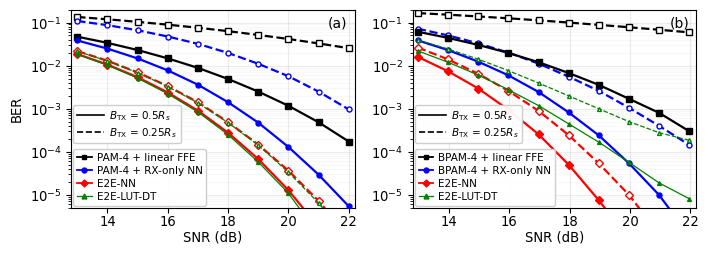

In [10]:
STYLE = {"linear": ("linear FFE", "s", "k"), "rx_only": ("RX-only NN", "o", "b"),       # name, marker, colour
         "e2e": ("E2E-NN", "D", "r"), "trees": ("E2E-LUT-DT", "^", "g")}
FORMAT_NAME = {"pam4": "PAM-4", "bpam": "BPAM-4"}
BANDS = sorted(TX_BANDWIDTH_GHZ, reverse=True)
LINE = {b: ("-", "--", "-.", ":")[i % 4] for i, b in enumerate(BANDS)}   # line style per TX filter bandwidth
WIDTH = 1.6                                     # line width of every curve but the trees
FONT, LEGEND_FONT = 9.5, 7.5
FIGURE_HEIGHT = 2.45                            # inches; the width is 3.5 inches per panel
BER_RANGE = (5e-6, .2)
MIN_ERRORS = 10
LEGEND_PAD = .2                                 # distance of the legends from the axes, in units of the legend font size
LEGEND_GAP = .55                                # gap between the two legends, in units of the legend font size
FIGURE_METHODS = METHODS + (["trees"] if trees else [])


def below_grid(regime):
    """Integer levels on the axis below the evaluation grid: counted by extra_points."""
    low = SNR_RANGE_DB[0] - SHIFT[regime] - .2
    return [float(l) for l in range(int(np.ceil(low)), int(min(EVALUATION_LEVEL_DB[regime])))]


extra = {}
for regime in REGIMES:
    for band in BANDS:
        case = make_case(regime, band)
        reference, levels = reference_case(case), below_grid(regime)
        extra[case.name] = extra_points(reference, WORK, BUDGET, levels, METHODS, device) if levels else {}
        if levels and case != reference:            # "zero-mean": its E2E-NN
            extra[case.name]["e2e"] = extra_points(case, WORK, BUDGET, levels, ["e2e"], device)["e2e"]


def curve(case, method, low, high):
    """Integer levels within [low, high] (levels of the regime) with at least MIN_ERRORS errors, on the SNR axis."""
    if method == "trees":
        points = trees[case.name]["points"]
    else:
        points = {**summaries[case.name]["results"][method]["points"]["reference"], **extra[case.name].get(method, {})}
    rows = sorted((float(l), r) for l, r in points.items())
    rows = [(x, r) for x, r in rows if x == int(x) and low <= x <= high and r["errors"] >= MIN_ERRORS]
    return [x + SHIFT[case.regime] for x, _ in rows], [r["ber"] for _, r in rows]


plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": FONT, "pdf.fonttype": 42})
fig, axes = plt.subplots(1, len(REGIMES), figsize=(3.5 * len(REGIMES), FIGURE_HEIGHT), sharey=True, squeeze=False)
low, high = SNR_RANGE_DB
for ax, regime in zip(axes[0], REGIMES):
    for band in BANDS:
        wide = band == BANDS[0]
        for method in FIGURE_METHODS:
            x, y = curve(make_case(regime, band), method, low - SHIFT[regime] - .2, high - SHIFT[regime] + .2)
            colour, thin = STYLE[method][2], method == "trees"
            ax.semilogy(x, y, color=colour, ls=LINE[band], marker=STYLE[method][1],
                        markersize=2.8 if thin else 1.2 + 1.5 * WIDTH, linewidth=.9 if thin else WIDTH,
                        markerfacecolor=colour if wide else "white", zorder=(5 if thin else 3) - (0 if wide else 1))
    ax.set_xlim(low - .2, high + .2)
    ax.set_xticks([t for t in range(low, high + 1) if t % 2 == 0])
    ax.set_ylim(*BER_RANGE)
    # panel letter inside the axes, (a) thermal noise, (b) ASE noise
    ax.text(.975, .965, f"({'ab'[['electrical', 'optical'].index(regime)]})", transform=ax.transAxes,
            ha="right", va="top", fontsize=10)
    ax.set_xlabel("SNR (dB)")
    ax.tick_params(axis="x", pad=1.5)           # tick labels and axis label close to the axis
    ax.xaxis.labelpad = 1.
    ax.tick_params(labelleft=True)              # BER scale on every panel
    ax.grid(which="major", alpha=.25)
    ax.grid(which="minor", axis="y", alpha=.08)
axes[0, 0].set_ylabel("BER")
fig.tight_layout(pad=.4, w_pad=1.0)
legend_style = dict(loc="lower left", fontsize=LEGEND_FONT, framealpha=.95, labelspacing=.3, borderpad=.35,
                    handletextpad=.5, borderaxespad=LEGEND_PAD)

for ax, regime in zip(axes[0], REGIMES):
    # method legend in the lower-left corner, bandwidth legend right above it
    fmt = FORMAT_NAME[FORMAT[regime]]
    names = {"linear": f"{fmt} + linear FFE", "rx_only": f"{fmt} + RX-only NN",
             "e2e": STYLE["e2e"][0], "trees": STYLE["trees"][0]}
    methods = ax.legend(handles=[Line2D([], [], color=STYLE[m][2], lw=.9 if m == "trees" else 1.3, marker=STYLE[m][1],
                                        markersize=3.5, label=names[m]) for m in FIGURE_METHODS],
                        handlelength=1.4, **legend_style)
    ax.add_artist(methods)
    fig.canvas.draw()
    top = methods.get_window_extent().transformed(ax.transAxes.inverted()).y1
    top -= (LEGEND_PAD - LEGEND_GAP) * LEGEND_FONT * fig.dpi / 72 / ax.bbox.height
    ax.legend(handles=[Line2D([], [], color="black", lw=1.2, ls=LINE[b],
                              label=rf"$B_{{\mathrm{{TX}}}}$ = {b / RS_GHZ:g}$R_s$") for b in BANDS],
              bbox_to_anchor=(0, top), handlelength=2.6, **legend_style)
fig.savefig(WORK / "ber_figure.pdf")
fig.savefig(WORK / "ber_figure.png", dpi=220)
plt.show()

## 8. Noiseless eyes

### Optical field at the modulator output

Panel (c) of Fig. 2: Re{E} at the MZM output without noise, for the widest TX filter bandwidth,
conventional and E2E TX of each noise regime, time in units of the symbol period 1/R_s. 32 samples
per symbol, 5000 symbols; the thermal-noise panels share the range of their traces, the ASE panels
are symmetric. Saved as `eye_row.pdf`.

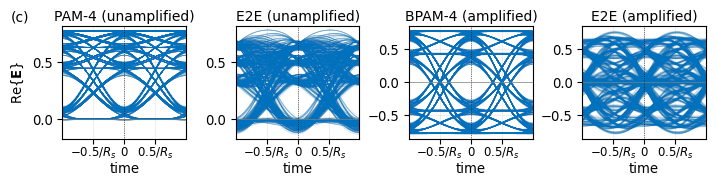

In [11]:
from matplotlib.ticker import MultipleLocator

LINK_NAME = {"electrical": "unamplified", "optical": "amplified"}
EYE_BAND = max(TX_BANDWIDTH_GHZ)
EYE_HEIGHT = 1.7                                # inches; the width is 1.75 inches per panel
panels = []
for regime in REGIMES:
    for arm in ("rx_only", "e2e"):
        with np.load(summaries[make_case(regime, EYE_BAND).name]["eyes"][arm]) as stored:
            name = FORMAT_NAME[FORMAT[regime]] if arm == "rx_only" else "E2E"
            panels.append((regime, arm, f"{name} ({LINK_NAME[regime]})", int(stored["sps"]), stored["field_real"].copy()))
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": FONT, "pdf.fonttype": 42})
fig, axes = plt.subplots(1, len(panels), figsize=(1.75 * len(panels), EYE_HEIGHT), squeeze=False)
limits = {}
for regime in REGIMES:
    if FORMAT[regime] == "bpam":
        limits[regime] = (-.85, .85)
    else:                                       # the range of the traces of both transmitters, 4 % margin
        shown = np.concatenate([field[(np.arange(256, 5256) * sps)[:, None] + np.arange(-sps, sps + 1)[None, :]].ravel()
                                for r, arm, name, sps, field in panels if r == regime])
        margin = .04 * (shown.max() - shown.min())
        limits[regime] = (shown.min() - margin, shown.max() + margin)
for k, (ax, (regime, arm, name, sps, field)) in enumerate(zip(axes[0], panels)):
    centres, offsets = np.arange(256, 5256) * sps, np.arange(-sps, sps + 1)
    traces = field[centres[:, None] + offsets[None, :]]
    ax.add_collection(LineCollection(np.stack([np.broadcast_to(offsets / sps, traces.shape), traces], -1),
                                     colors="#0072BD", alpha=.03 if arm == "rx_only" else .04, linewidths=.5,
                                     rasterized=True))
    ax.set_xlim(-1, 1); ax.set_xticks([-.5, 0, .5]); ax.set_ylim(*limits[regime])
    ax.set_xticklabels([r"$-0.5/R_s$", "0", r"$0.5/R_s$"])
    ax.tick_params(axis="x", labelsize=8.5, pad=1.5)
    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.axvline(0, color="black", lw=.5, ls=":"); ax.axhline(0, color="gray", lw=.5)
    ax.grid(alpha=.2)
    ax.set_title(name, fontsize=10, pad=3.5)
    ax.set_xlabel("time", labelpad=1.)
    if k == 0:
        ax.set_ylabel(r"Re$\{\mathbf{E}\}$")
fig.tight_layout(pad=.15, h_pad=.4, w_pad=.6)
fig.text(.004, .985, "(c)", fontsize=10, ha="left", va="top")
fig.savefig(WORK / "eye_row.pdf", dpi=300)
fig.savefig(WORK / "eye_row.png", dpi=200)
plt.show()

### Pre/post-modulator eyes

One figure per TX filter bandwidth. Rows: conventional TX and E2E TX of each noise regime.
Columns: drive voltage (V/Vπ), modulator output field Re{E} and power |E|², not normalized.
32 samples per symbol, 5000 symbols. At the DAC instants (0 and ±T/2) the E2E traces pass
through the levels of the DAC.

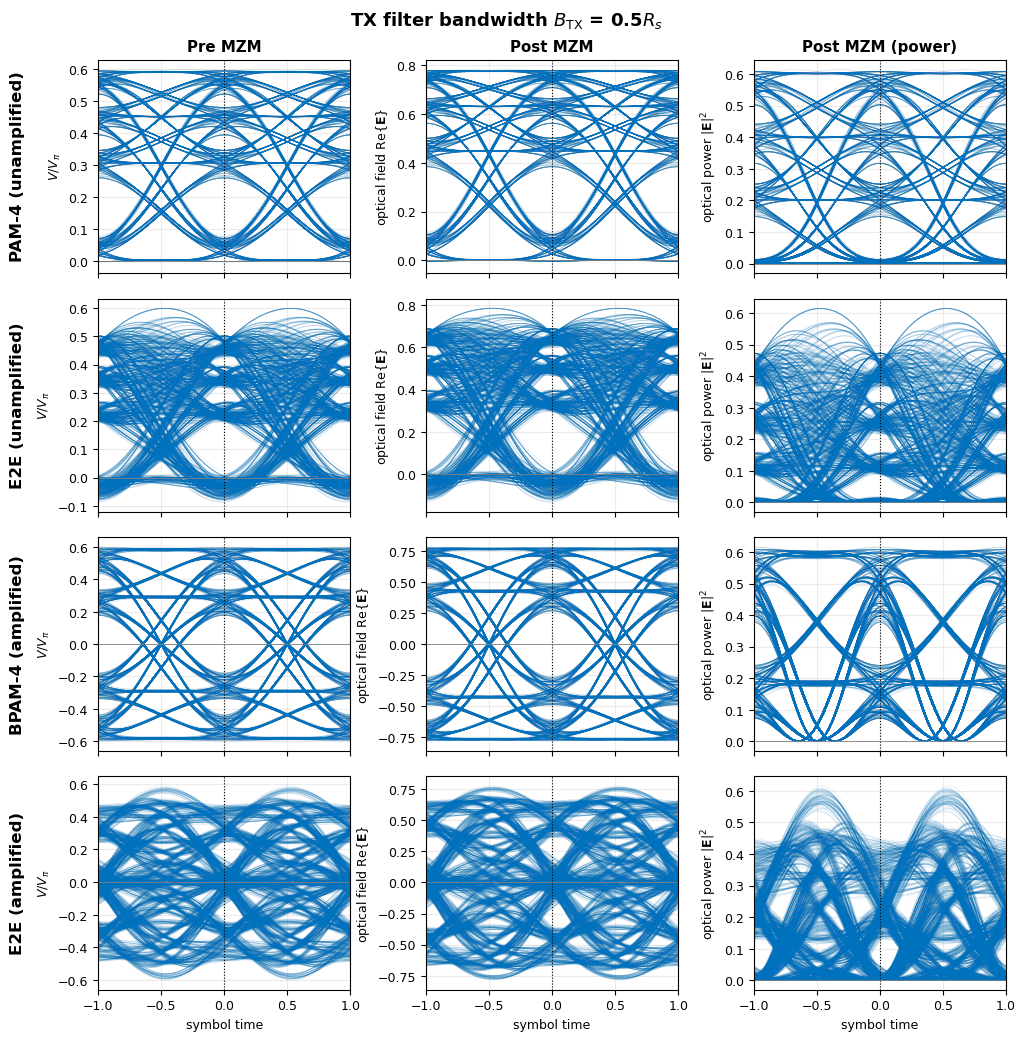

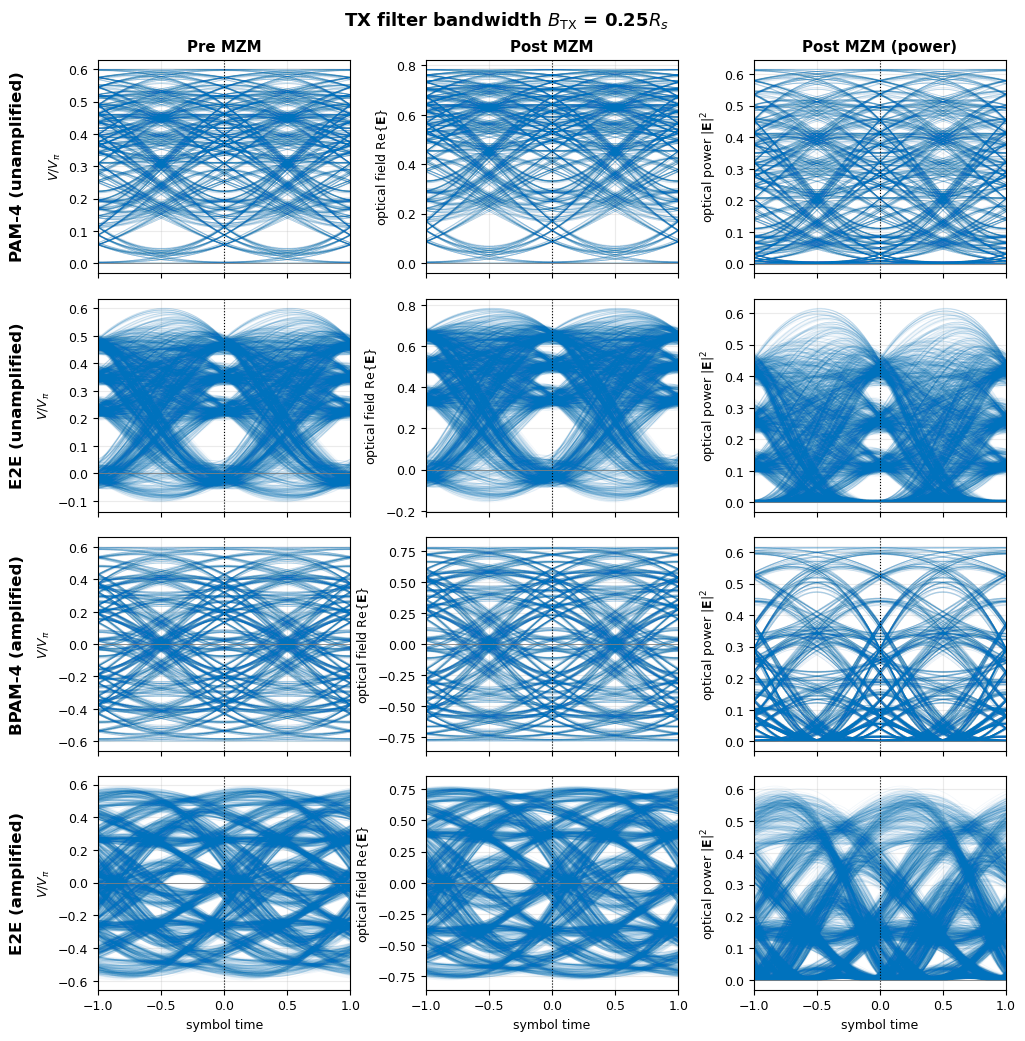

In [12]:
TRACE_COLORS = ("#0072BD", "#0072BD", "#0072BD")
YLABELS = (r"$V/V_\pi$", r"optical field $\mathrm{Re}\{\mathbf{E}\}$", r"optical power $|\mathbf{E}|^2$")
TITLES = ("Pre MZM", "Post MZM", "Post MZM (power)")
ALPHA = {"rx_only": .03, "e2e": .05}
plt.rcParams.update({"font.size": 9})
for band in TX_BANDWIDTH_GHZ:
    rows = [(regime, arm) for regime in REGIMES for arm in ("rx_only", "e2e")]
    fig, axes = plt.subplots(len(rows), 3, figsize=(10.2, 2.65 * len(rows)), sharex=True, squeeze=False)
    for row, (regime, arm) in enumerate(rows):
        with np.load(summaries[make_case(regime, band).name]["eyes"][arm]) as stored:   # read and close the file
            data = dict(stored)
        sps = int(data["sps"])
        field = data["field_real"] + 1j * data["field_imag"]
        signals = (data["drive"] / float(data["vpi"]), field.real, np.abs(field) ** 2)
        centres, offsets = np.arange(256, 5256) * sps, np.arange(-sps, sps + 1)
        for col, values in enumerate(signals):
            traces = values[centres[:, None] + offsets[None, :]]
            ax = axes[row, col]
            ax.add_collection(LineCollection(np.stack([np.broadcast_to(offsets / sps, traces.shape), traces], -1),
                                             colors=TRACE_COLORS[col], alpha=ALPHA[arm], linewidths=.6, rasterized=True))
            ax.autoscale_view()
            ax.set_xlim(-1, 1); ax.set_xticks([-1, -.5, 0, .5, 1])
            ax.axvline(0, color="black", lw=.8, ls=":"); ax.axhline(0, color="gray", lw=.6)
            ax.grid(alpha=.25); ax.set_ylabel(YLABELS[col])
            if row == 0:
                ax.set_title(TITLES[col], fontweight="bold")
            if row == len(rows) - 1:
                ax.set_xlabel("symbol time")
        label = f"{FORMAT_NAME[FORMAT[regime]] if arm == 'rx_only' else 'E2E'} ({LINK_NAME[regime]})"
        axes[row, 0].text(-.32, .5, label, transform=axes[row, 0].transAxes, rotation=90,
                          va="center", ha="center", fontsize=12, fontweight="bold")
    fig.suptitle(rf"TX filter bandwidth $B_\mathrm{{TX}}$ = {band / RS_GHZ:g}$R_s$", fontsize=13,
                 fontweight="bold")
    fig.subplots_adjust(left=.1, right=.99, top=1 - .27 / len(rows), bottom=.22 / len(rows), hspace=.12, wspace=.3)
    fig.savefig(WORK / f"eyes_bw{band}.png", dpi=200)
    fig.savefig(WORK / f"eyes_bw{band}.pdf", dpi=200)
    plt.show()

## 9. Variants

Each variant against its base configuration: SNR at BER 1e-3 on the reference simulator.

In [13]:
rows = ["| Variant | Base configuration | RX-only NN: base / variant | E2E-NN: base / variant |", "|---|---|---:|---:|"]
for case in EXTRA:
    base = make_case(case.regime, case.tx_bandwidth_ghz)
    rows.append(f"| {case.label} | {base.name} | {text(required_snr(summaries[base.name], 'rx_only', case.regime))} / "
                f"{text(required_snr(summaries[case.name], 'rx_only', case.regime))} | "
                f"{text(required_snr(summaries[base.name], 'e2e', case.regime))} / "
                f"{text(required_snr(summaries[case.name], 'e2e', case.regime))} |")
display(Markdown("\n".join(rows) + "\n\nSNR (Es/N0) at BER 1e-3 in dB."))

| Variant | Base configuration | RX-only NN: base / variant | E2E-NN: base / variant |
|---|---|---:|---:|

SNR (Es/N0) at BER 1e-3 in dB.